# Pjesa I · 3/4: Krijimi i vetive dhe kodimi

**Qëllimi:** nga tabela e pastruar krijojmë veti të reja që ndihmojnë analizën e çmimit për natë. Pas krijimit, notebook-u vazhdon me diskretizimin, binarizimin dhe kodimin.

**Hyrja:** `dataset/listings_clean_full.csv`, tabela e plotë e pastruar nga notebook-u 02 (të gjitha kolonat, para zgjedhjes së 18 kolonave). Ekzekutoni së pari notebook-un 02. Dataset-i origjinal nuk ndryshohet.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_clean_full.csv").is_file() and (ROOT.parent / "dataset" / "listings_clean_full.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_clean_full.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 02."
df = pd.read_csv(DATA_PATH, low_memory=False, parse_dates=["last_scraped", "last_review"])
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_clean_full.csv | Rreshta: 59,905 | Kolona: 81


## 1. Distanca nga qendra e Londrës

Vendndodhja ndikon fort te çmimi, por `latitude` dhe `longitude` veç e veç nuk kanë kuptim të drejtpërdrejtë. Si qendër marrim **Charing Cross** (51.5073, −0.1276), pikën tradicionale nga e cila maten distancat në Londër. Distancën në km e llogarisim me formulën *haversine*, e cila merr parasysh lakimin e Tokës.

In [2]:
CENTER_LAT, CENTER_LON = 51.5073, -0.1276
EARTH_RADIUS_KM = 6371.0

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat) * np.cos(lat0) * np.sin((lon - lon0) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))

df["distance_to_center_km"] = haversine_km(df["latitude"], df["longitude"], CENTER_LAT, CENTER_LON)
display(df["distance_to_center_km"].describe().round(2).to_frame())
display(df.groupby(pd.cut(df["distance_to_center_km"], [0, 2, 5, 10, 20, 40]), observed=True)["price"].median().to_frame("çmimi median"))

,distance_to_center_km
count,59905.00
mean,7.66
std,5.14
min,0.03
25%,3.83
50%,6.17
75%,10.55
max,30.70


,çmimi median
distance_to_center_km,
"(0, 2]",325.00
"(2, 5]",220.00
"(5, 10]",159.00
"(10, 20]",123.33
"(20, 40]",101.49


## 2. Përvoja e host-it

`hosts_time_as_host_years` jep vitet e plota, ndërsa `hosts_time_as_host_months` muajt e mbetur (0–11). I bashkojmë në një vlerë të vetme në vite.

In [3]:
df["host_tenure_years"] = df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12
display(df["host_tenure_years"].describe().round(2).to_frame())

,host_tenure_years
count,59905.00
mean,5.37
std,4.06
min,0.00
25%,2.00
50%,4.08
75%,8.83
max,15.67


## 3. Host me shumë listime

`calculated_host_listings_count` numëron listimet e host-it në këtë dataset. E përdorim atë dhe jo `host_listings_count`, sepse ky i fundit vjen nga Airbnb, arrin deri në 5,777 dhe në disa listime është më i vogël se numri i listimeve që shohim vetë në dataset, pra nuk është i qëndrueshëm. Host-i me më shumë se një listim shpesh është menaxher profesional.

In [4]:
df["is_multi_listing_host"] = df["calculated_host_listings_count"].gt(1)
print(f"Listime nga host-e me shumë listime: {df['is_multi_listing_host'].mean():.1%}")
display(df.groupby("is_multi_listing_host")["price"].agg(["count", "median"]).round(2))

Listime nga host-e me shumë listime: 65.5%


,count,median
is_multi_listing_host,,
False,20659,155.0
True,39246,187.5


## 4. Çmimi për person

`price / accommodates` lejon krahasimin e listimeve me kapacitet të ndryshëm. **Kujdes:** kjo veti është krijuar nga çmimi, prandaj nuk duhet përdorur si hyrje e modelit kur çmimi është variabla që parashikohet.

In [5]:
df["price_per_person"] = df["price"] / df["accommodates"]
display(df["price_per_person"].describe().round(2).to_frame())

,price_per_person
count,59905.00
mean,75.58
std,349.59
min,1.50
25%,39.60
50%,55.60
75%,80.97
max,75000.00


## 5. Ditë nga komenti i fundit

Tregon sa aktiv është listimi. Llogaritet nga data e mbledhjes (`last_scraped`) dhe jo nga data e sotme, që rezultati të mos ndryshojë sa herë ekzekutohet notebook-u. Për listimet pa komente vlera mbetet bosh me qëllim: `has_reviews` e mbulon këtë rast.

In [6]:
df["days_since_last_review"] = (df["last_scraped"] - df["last_review"]).dt.days
print(f"Bosh (pa komente): {df['days_since_last_review'].isna().sum():,} | Negative: {int(df['days_since_last_review'].lt(0).sum())}")
display(df["days_since_last_review"].describe().round(1).to_frame())

Bosh (pa komente): 12,258 | Negative: 0


,days_since_last_review
count,47647.0
mean,206.5
std,444.0
min,0.0
25%,16.0
50%,39.0
75%,144.0
max,5289.0


## 6. Kontrolli i vetive të reja

Për secilën veti kontrollojmë mungesat dhe shpërndarjen. `price_per_person` dhe `days_since_last_review` janë shumë asimetrike; kjo trajtohet te transformimi në notebook-un 04.

,bosh
distance_to_center_km,0
host_tenure_years,0
is_multi_listing_host,0
price_per_person,0
days_since_last_review,12258


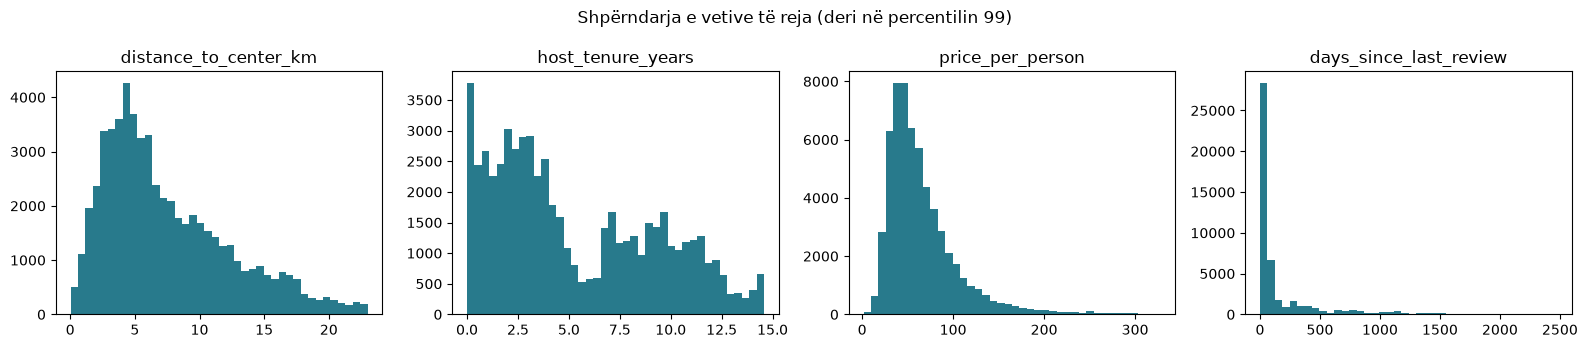

In [7]:
new_features = ["distance_to_center_km", "host_tenure_years", "is_multi_listing_host", "price_per_person", "days_since_last_review"]
display(df[new_features].isna().sum().to_frame("bosh"))
numeric = [col for col in new_features if col != "is_multi_listing_host"]
fig, axes = plt.subplots(1, len(numeric), figsize=(16, 3.5))
for ax, col in zip(axes, numeric):
    values = df[col].dropna()
    values[values.le(values.quantile(0.99))].plot.hist(bins=40, ax=ax, color="#287a8c")
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Shpërndarja e vetive të reja (deri në percentilin 99)")
plt.tight_layout()
plt.show()

**Vazhdon:** grupimi i `property_type`, analiza e `amenities`, diskretizimi dhe kodimi.